# t-SNE: Do High- and Low-Growth Students Separate?
Owner: Anupama Singh

t-SNE (t-distributed Stochastic Neighbor Embedding) draws the 16-dimensional data as a 2D picture: students who are
similar across the 16 fall features are placed close together.

**Question:** in the fall data alone, do high-growth and low-growth students form separate groups? If they are mixed
together, that explains why every model (ours, the team's and the paper's) tops out around ROC AUC 0.67.

**How to read t-SNE:**
- Points that sit close together are similar students.
- Colors that form separate regions mean the classes are easy to tell apart.
- The x and y axes have no meaning, and distances between clusters are not reliable.
- t-SNE is a picture, not a model. The numeric check in section 4 backs it up.

## 1. Setup and data
Same data as the paper and as the rest of the team: 706 labeled students with no missing values, the paper's 16 features, two targets. The folds are identical to Megha's Random Forest and XGBoost notebooks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, mean_absolute_error
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
# Data: local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

# Outputs: the repo's results/ folder when run locally, ./results in Colab
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

# The paper's 16 features (Table 3) and the two Woodcock targets
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)

# Spring scores are used ONLY to compute the gain (regression target), never as features
spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")

# Labeled students with no missing feature values, as in the paper (706 students)
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")

Students: 706 | Schools: 42 | Features: 16


## 2. Run t-SNE
Features are standardized first (mean 0, standard deviation 1); otherwise large-scale features such as the Stanford
scores (around 450) would dominate small ones such as `Gender` (0 or 1).

- `perplexity=30`: roughly how many neighbors each point pays attention to (the usual default).
- `random_state=0`: fixes the layout so every run gives the same picture.

In [2]:
X_scaled = StandardScaler().fit_transform(X)


def run_tsne(perplexity=30):
    return TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto",
                random_state=0).fit_transform(X_scaled)


embedding = run_tsne(30)
print("t-SNE layout:", embedding.shape)

t-SNE layout: (706, 2)


## 3. The picture
Three versions of the same layout, colored by:
1. Word Identification label
2. Word Attack label
3. Intervention group (`Tx`), as a check: does the treatment group form its own cluster?

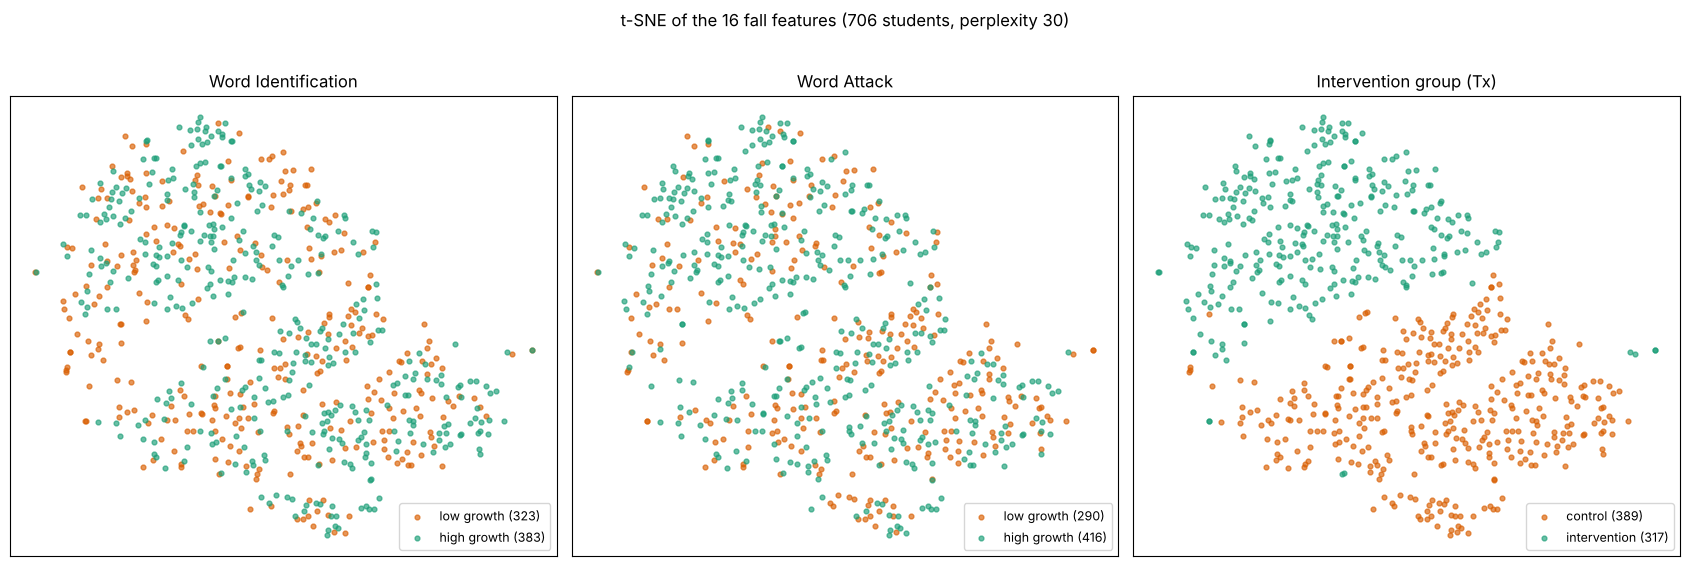

In [3]:
LOW, HIGH = "#d95f02", "#1b9e77"
panels = [("Word Identification", data["RMwidRS_target"], ("low growth", "high growth")),
          ("Word Attack", data["RMwdaRS_target"], ("low growth", "high growth")),
          ("Intervention group (Tx)", data["Tx"], ("control", "intervention"))]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (title, values, names) in zip(axes, panels):
    for value, color, name in [(0, LOW, names[0]), (1, HIGH, names[1])]:
        mask = values.astype(int).values == value
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=12, alpha=0.65, color=color,
                   label=f"{name} ({mask.sum()})")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle(f"t-SNE of the 16 fall features ({len(data)} students, perplexity 30)", y=1.02)
plt.tight_layout()
plt.savefig(RESULTS / "tsne_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Numeric check: how mixed are the classes?
For each student, look at their 10 most similar students in the original 16 standardized features and count how many
share their label. If the classes were well separated, this would be close to 100%. If they are fully mixed, it is
about what you would get by chance.

"Chance" = the share of same-label neighbors expected if labels were shuffled: p² + (1 − p)², where p is the share
of label 1.

In [4]:
neighbors = NearestNeighbors(n_neighbors=11).fit(X_scaled)
_, idx = neighbors.kneighbors(X_scaled)
idx = idx[:, 1:]                                  # drop the student themself

rows = []
for title, values, _ in panels:
    labels = values.astype(int).values
    same = (labels[idx] == labels[:, None]).mean()
    p = labels.mean()
    rows.append({"colored by": title, "same label among 10 nearest neighbors": round(same, 3),
                 "expected by chance": round(p ** 2 + (1 - p) ** 2, 3),
                 "difference": round(same - (p ** 2 + (1 - p) ** 2), 3)})
mixing = pd.DataFrame(rows)
mixing.to_csv(RESULTS / "tsne_neighbor_label_agreement.csv", index=False)
mixing

,colored by,same label among 10 nearest neighbors,expected by chance,difference
0,Word Identification,0.552,0.504,0.048
1,Word Attack,0.542,0.516,0.026
2,Intervention group (Tx),0.955,0.505,0.450


## 5. Does the picture depend on perplexity?
t-SNE pictures can change with the perplexity setting. If the high- and low-growth students stay mixed at every
setting, the conclusion does not depend on this choice. Shown for Word Identification.

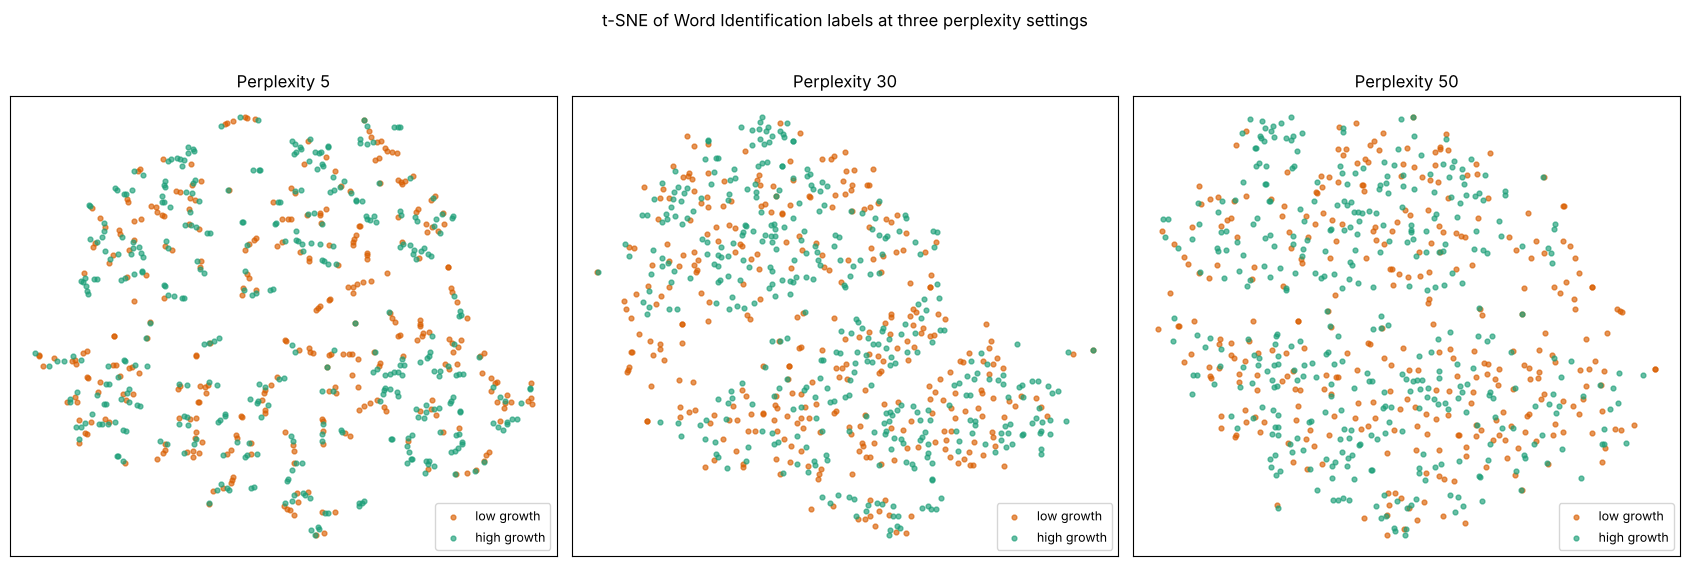

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
labels = data["RMwidRS_target"].astype(int).values
for ax, perplexity in zip(axes, [5, 30, 50]):
    layout = embedding if perplexity == 30 else run_tsne(perplexity)
    for value, color, name in [(0, LOW, "low growth"), (1, HIGH, "high growth")]:
        mask = labels == value
        ax.scatter(layout[mask, 0], layout[mask, 1], s=12, alpha=0.65, color=color, label=name)
    ax.set_title(f"Perplexity {perplexity}")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle("t-SNE of Word Identification labels at three perplexity settings", y=1.02)
plt.tight_layout()
plt.savefig(RESULTS / "tsne_perplexity_check.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. What it means
- **High- and low-growth students are mixed together.** Among each student's 10 most similar students, only 55% share
  their Word Identification label (54% for Word Attack), against 50% by chance. The fall features carry only a weak
  signal about who will grow, which matches the ROC AUC ceiling of about 0.67 for every model.
- **The intervention group separates almost perfectly** (96% same-label neighbors vs 50% by chance). `Tx` is tied to
  the classroom-observation features (`grp_rate` r = 0.69, `gnrl_fid` r = 0.64), so the strongest structure in the data
  is which classroom setting a student was in, not how much they will grow.
- **The picture does not depend on perplexity:** at 5, 30 and 50 the growth labels stay mixed.
- These plots use the raw features. Supriya's t-SNE (paper Figure 3) uses the MLP and MaskMLP embeddings instead,
  so compare the two only in words.